# Plot a radial cell annotation tree

Use `ov.pl.celltype_tree()` to draw a cell classification as a radial tree. In this example, each leaf represents one PBMC cell type. Four rings show marker expression, and the outer labels give cell proportions.

## Summarize the PBMC data

Load the [reduced 10x PBMC dataset bundled with Scanpy](https://scanpy.readthedocs.io/en/latest/api/generated/scanpy.datasets.pbmc68k_reduced.html). Use its `bulk_labels` annotations and assign each label to a lineage and a family. Average log-normalized expression within each cell type, then standardize each gene across the cell-type means. The result has one row per leaf.

In [1]:
import pandas as pd
import scanpy as sc
import omicverse as ov

adata = sc.datasets.pbmc68k_reduced()
genes = ["IL7R", "MS4A1", "NKG7", "LYZ"]
labels = adata.obs["bulk_labels"]
if adata.raw is not None:
    expression = adata.raw.to_adata()[:, genes].to_df()
else:
    expression = adata[:, genes].to_df(layer="log_counts")

annotations = pd.DataFrame.from_dict({
    "CD4+/CD45RA+/CD25- Naive T": ("T cells", "CD4 T", "Naive CD4 T"),
    "CD4+/CD45RO+ Memory": ("T cells", "CD4 T", "Memory CD4 T"),
    "CD4+/CD25 T Reg": ("T cells", "CD4 T", "Regulatory T"),
    "CD8+/CD45RA+ Naive Cytotoxic": ("T cells", "CD8 T", "Naive CD8 T"),
    "CD8+ Cytotoxic T": ("T cells", "CD8 T", "Cytotoxic CD8 T"),
    "CD19+ B": ("B cells", "B cells", "CD19+ B"),
    "CD56+ NK": ("NK cells", "NK cells", "CD56+ NK"),
    "CD14+ Monocyte": ("Myeloid", "Monocytes", "CD14+ monocytes"),
    "Dendritic": ("Myeloid", "Dendritic", "Dendritic cells"),
    "CD34+": ("Progenitors", "CD34+", "CD34+ cells"),
}, orient="index", columns=["lineage", "family", "cell_type"])

means = expression.groupby(labels, observed=True).mean().reindex(annotations.index)
celltypes = annotations.copy()
celltypes["percent"] = 100 * labels.value_counts().reindex(annotations.index) / adata.n_obs
celltypes[genes] = (means - means.mean()) / means.std(ddof=0).replace(0, 1)
print(f"{adata.n_obs} cells, {len(celltypes)} cell types, {len(genes)} tracks")

700 cells, 10 cell types, 4 tracks


## Draw the tree and tracks

Pass the hierarchy columns from broad to fine. The plot keeps each subtree together and draws the tracks in the order you pass them, from the inner ring to the outer ring.

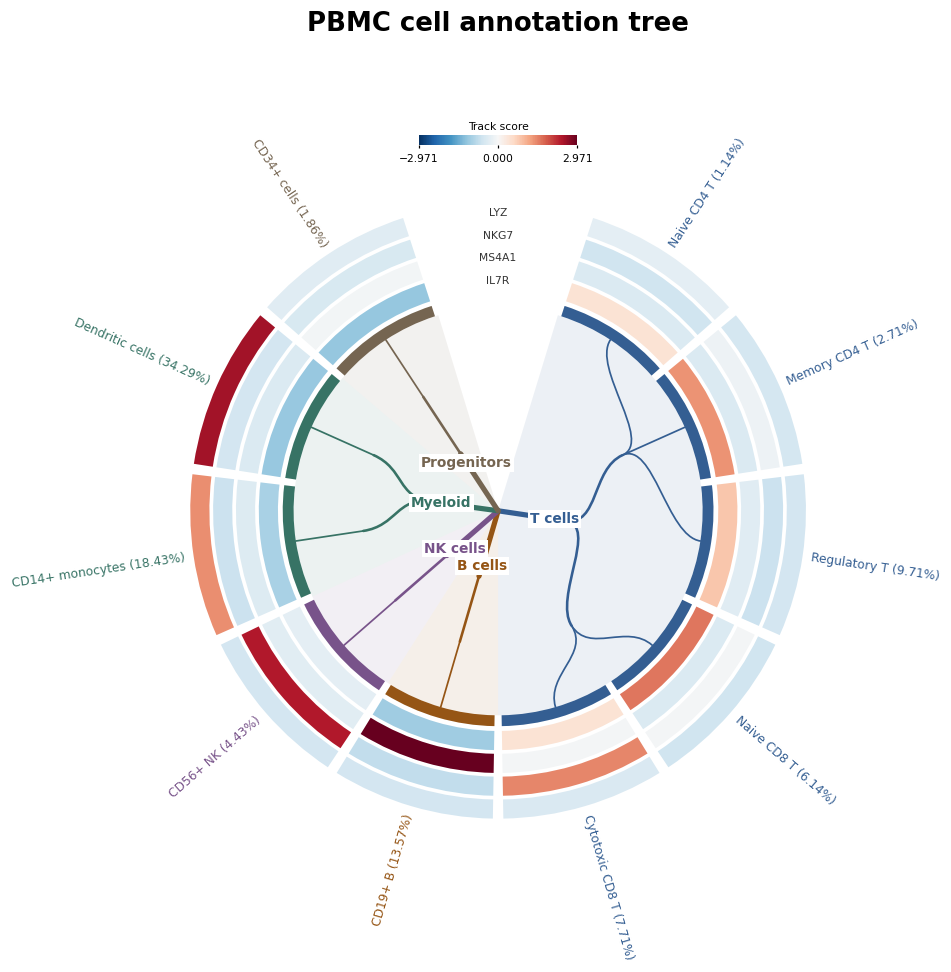

In [2]:
ax = ov.pl.celltype_tree(
    celltypes,
    hierarchy=["lineage", "family"],
    label="cell_type",
    proportion="percent",
    tracks=genes,
    palette={
        "T cells": "#345E92",
        "B cells": "#955515",
        "NK cells": "#78538A",
        "Myeloid": "#377365",
        "Progenitors": "#756551",
    },
    figsize=(9, 9),
    show=False,
)
ax.figure.subplots_adjust(left=0.025, right=0.975, bottom=0.03, top=0.92)
ax.figure.suptitle("PBMC cell annotation tree", fontsize=17, fontweight="semibold")
ax.figure

The figure shows ten cell types and four rings. A red tile means that the cell-type mean is above the mean across types for that gene. A blue tile means it is below. Percentages describe this bundled dataset.

## Use your own cell types

Prepare a DataFrame with a unique combination of hierarchy and leaf label per row. Choose the row order to set the first appearance of sibling groups. The function keeps each subtree contiguous even when the rows are interleaved.

- `proportion` names an optional column of percentages between 0 and 100.
- `tracks` names numeric columns. Each ring reads its own column. Missing values appear gray.
- `track_markers` maps a track to a column of precomputed text markers, such as significance stars.
- `palette` maps the first hierarchy level to colors. `cmap` and `vmax` control the shared, zero-centered track scale. Use comparable units across tracks.

See the [parameter reference](../api/reference/omicverse.pl.celltype_tree.rst) for defaults. To save the result, use the figure attached to the returned `Axes`.

In [ ]:
ax.figure.savefig("pbmc-celltype-tree.pdf", bbox_inches="tight")

## Figure inspiration

The layout follows the idea of the cell annotation tree in [Yin et al., *Chinese Immune Multi-Omics Atlas*](https://doi.org/10.1126/science.adt3130) and the accompanying [visualization walkthrough](https://mp.weixin.qq.com/s/F7cgHFmpEAhwhrzAN0NvUA).